# MIMO predicting multiple outcomes from multiple stats.

This final network combines everything: three inputs (CS@10, gold diff@10, kills@10)

To predict three separate outputs (win probability, objective control chance, late-game scaling advantage)

Makese use of a weight matrix where each output has its own row of three weights, one per input

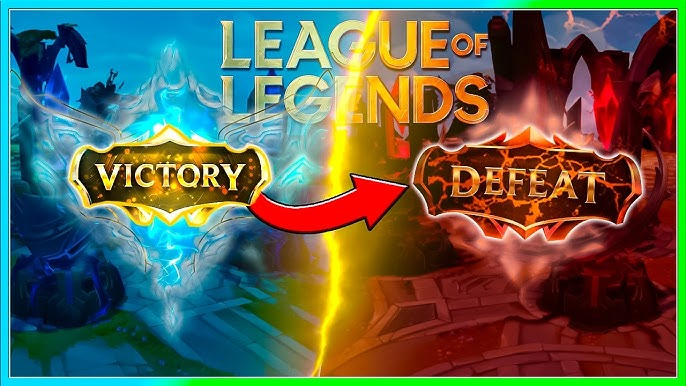


In [1]:
            #CS    #gold    #kills
weights = [ [0.005, 0.0003, 0.02],   # win_probability
            [0.001, 0.0002, 0.05],   # objective_control_chance
            [0.002, 0.0001, 0.01] ]  # late_game_scaling_advantage

def w_sum(a, b):
    assert(len(a) == len(b))
    output = 0
    for i in range(len(a)):
        output += (a[i] * b[i])
    return output

def vect_mat_mul(vect, matrix):
    assert(len(vect) == len(matrix))
    output = [0, 0, 0]
    for i in range(len(vect)):
        output[i] = w_sum(vect, matrix[i])
    return output

def neural_network(input, weights):
    pred = vect_mat_mul(input, weights)
    return pred

cs_at_10     = [75, 68, 82, 60]
gold_diff_10 = [450, -200, 900, -600]
kills_at_10  = [3, 1, 6, 0]

input = [cs_at_10[0], gold_diff_10[0], kills_at_10[0]]
pred = neural_network(input, weights)
print(pred)

[0.5700000000000001, 0.31500000000000006, 0.225]


# Understadning the Output

For game 1 (CS=75, gold=+450, kills=3),

the model predicts: win probability ≈ 0.57, objective control chance ≈ 0.315, late-game scaling ≈ 0.225.

Kills carry larger weights (0.02-0.05) than for  example gold diff(0.0001-0.0003) as kills are small numbers for example 3 while gold diff is in hundreds.


Note! still no bias nor activation function so outputs can exceed sensible ranges


# Experimentation

Changing weights in the matrix for example raising weights[1][2] which are kills->obj control shows how one row change, effects one output.

Update input = [cs_at_10[0], gold_diff_10[0], kills_at_10[0]] to [1],[2] shows the other games that are recorded.

For example for game 2 [68, -200, 1] gives [0.30, 0.078, 0.126], a much weaker prediction across all 3 fields

#